# `lcz_get_lst` Tutorial — Land Surface Temperature from Microsoft Planetary Computer

Downloads a daily LST time-series stack from either **GOES-R ABI-L2-LST**
(Americas, ~2km, CONUS) or **Sentinel-3 SLSTR LST** (global, ~1km), cropped
to an existing LCZ map's footprint. No API key required — both sources use
Microsoft Planetary Computer's public STAC/SAS endpoints.

Run cells top-to-bottom. §1 downloads the LCZ map used by every later section.

**Notes on data availability (checked live against the real API):**
- The GOES archive on Planetary Computer currently only has data through
  **~April 2025** — dates after that will legitimately return no scenes.
- GOES LST is cloud/quality-masked, so scenes are often sparse (a large
  NaN fraction is expected, not a bug).
- Sentinel-3 only covers a city 1-2 times/day, so short date ranges may
  skip some days if no overpass intersected the area.
- `lcz_get_lst` returns temperature in **Celsius by default** (`units="C"`);
  pass `units="K"` for Kelvin. The on-disk cache always stores Kelvin
  internally, so switching `units` never triggers a re-download.

In [ ]:
import sys, os
sys.path.insert(0, os.getcwd())

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

from LCZ4py import lcz_get_map
from LCZ4py import lcz_get_lst
from LCZ4py import lcz_plot_map
from LCZ4py import lcz_uhi_surface
import polars as pl

## 1 — Download an LCZ map (Chicago)

Chicago is used because it falls inside the GOES CONUS view, so both
sources can be tested against the same map.

In [2]:
map_path = lcz_get_map(city="Chicago", isave_map=False)
print("map_path:", map_path)

map_path: /Users/co2map/.lcz4r_cache/clipped_0917e0072dd1eafa.tif


---
## 2 — GOES-R ABI-L2-LST (CONUS)

One scene/day, picked nearest `target_hour` (UTC). The archive currently
covers 2017 through early 2025, so we use a date range known to have data.
Output is in Celsius (`units="C"`, the default).

In [3]:
lst_goes = lcz_get_lst(
    map_path,
    source="goes",
    start_date="2025-01-05",
    end_date="2025-01-09",
    target_hour=18.0,  # ~noon local time in Chicago (UTC-6)
    units="C",
    cache=True,
)

print("array shape (days, H, W):", lst_goes.array.shape)
print("units:", lst_goes.units)
print("dates:", lst_goes.dates)
for i, d in enumerate(lst_goes.dates):
    a = lst_goes.array[i]
    valid = ~np.isnan(a)
    print(f"  {d}: valid={valid.mean():.1%}  "
          f"mean={np.nanmean(a):.1f}°C  min={np.nanmin(a):.1f}  max={np.nanmax(a):.1f}")

array shape (days, H, W): (3, 422, 464)
units: C
dates: ['2025-01-07', '2025-01-08', '2025-01-09']
  2025-01-07: valid=0.1%  mean=-4.8°C  min=-5.2  max=-4.4
  2025-01-08: valid=5.4%  mean=1.3°C  min=-3.0  max=4.5
  2025-01-09: valid=34.8%  mean=4.1°C  min=1.5  max=5.8


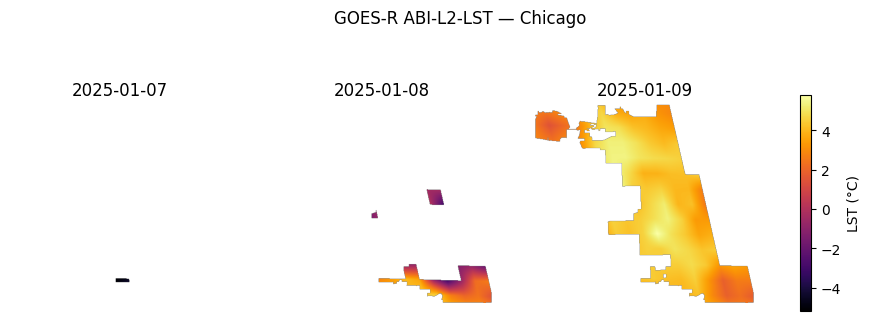

In [4]:
fig, axes = plt.subplots(1, len(lst_goes.dates), figsize=(4 * len(lst_goes.dates), 4))
if len(lst_goes.dates) == 1:
    axes = [axes]
vmin, vmax = np.nanmin(lst_goes.array), np.nanmax(lst_goes.array)
for ax, day, band in zip(axes, lst_goes.dates, lst_goes.array):
    im = ax.imshow(band, cmap="inferno", vmin=vmin, vmax=vmax)
    ax.set_title(day)
    ax.axis("off")
fig.colorbar(im, ax=axes, label="LST (°C)", shrink=0.7)
fig.suptitle("GOES-R ABI-L2-LST — Chicago")
plt.show()

### 2.1 — Static plot via `lcz_plot_map`

`lcz_plot_map` auto-detects the LST stack (float dtype) and plots one band
at a time — pick it by index or by matching a date. The colorbar label
comes from the GeoTIFF's `units` tag (also exposed as `lst_goes.units`).
Figures are static matplotlib by default; pass `renderer="plotly"` for the
interactive Plotly figure.

In [ ]:
plot_goes = lcz_plot_map(lst_goes.path, band=lst_goes.dates[-1])
# Units come from the LST stack itself (the on-disk cache always stores Kelvin).
print("units (K on disk, converted by lcz_get_lst):", lst_goes.units)
display(plot_goes.fig)

---
## 3 — Sentinel-3 SLSTR LST (global)

Global coverage, ~1-2 overpasses/day. Regridded from the native curvilinear
swath onto the LCZ map's grid via nearest-neighbor (`scipy.spatial.cKDTree`).

In [6]:
lst_s3 = lcz_get_lst(
    map_path,
    source="sentinel3",
    start_date="2026-06-01",
    end_date="2026-06-05",
    units="C",
    cache=True,
)

print("array shape (days, H, W):", lst_s3.array.shape)
print("units:", lst_s3.units)
print("dates:", lst_s3.dates)
for i, d in enumerate(lst_s3.dates):
    a = lst_s3.array[i]
    valid = ~np.isnan(a)
    print(f"  {d}: valid={valid.mean():.1%}  "
          f"mean={np.nanmean(a):.1f}°C  min={np.nanmin(a):.1f}  max={np.nanmax(a):.1f}")

array shape (days, H, W): (5, 422, 464)
units: C
dates: ['2026-06-01', '2026-06-02', '2026-06-03', '2026-06-04', '2026-06-05']
  2026-06-01: valid=41.6%  mean=3.7°C  min=-5.2  max=7.2
  2026-06-02: valid=13.3%  mean=32.8°C  min=20.1  max=36.7
  2026-06-03: valid=41.6%  mean=22.4°C  min=-10.8  max=39.4
  2026-06-04: valid=41.6%  mean=32.3°C  min=9.4  max=40.9
  2026-06-05: valid=41.6%  mean=-3.7°C  min=-28.7  max=26.3


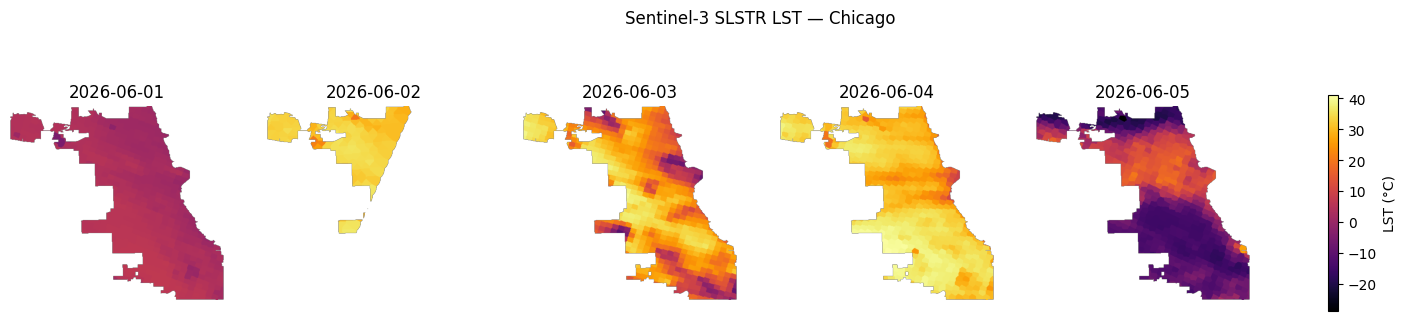

In [7]:
fig, axes = plt.subplots(1, len(lst_s3.dates), figsize=(4 * len(lst_s3.dates), 4))
vmin, vmax = np.nanmin(lst_s3.array), np.nanmax(lst_s3.array)
for ax, day, band in zip(axes, lst_s3.dates, lst_s3.array):
    im = ax.imshow(band, cmap="inferno", vmin=vmin, vmax=vmax)
    ax.set_title(day)
    ax.axis("off")
fig.colorbar(im, ax=axes, label="LST (°C)", shrink=0.7)
fig.suptitle("Sentinel-3 SLSTR LST — Chicago")
plt.show()

### 3.1 — Static plot via `lcz_plot_map`

Same call, different source. `band=None` (the default) plots the first
available date.

In [ ]:
plot_s3 = lcz_plot_map(lst_s3.path, title="Sentinel-3 LST — Chicago")
display(plot_s3.fig)

---
## 4 — `units="C"` vs `units="K"`

Both read from the same Kelvin cache file — passing a different `units`
never re-downloads anything, it only changes the conversion applied to the
returned array.

In [9]:
lst_s3_k = lcz_get_lst(
    map_path, source="sentinel3",
    start_date="2026-06-01", end_date="2026-06-02",
    units="K", cache=True,
)
lst_s3_c = lcz_get_lst(
    map_path, source="sentinel3",
    start_date="2026-06-01", end_date="2026-06-02",
    units="C", cache=True,
)
diff = np.nanmean(lst_s3_k.array) - np.nanmean(lst_s3_c.array)
print(f"K mean: {np.nanmean(lst_s3_k.array):.2f}, C mean: {np.nanmean(lst_s3_c.array):.2f}, diff: {diff:.2f} (expect 273.15)")

K mean: 283.89, C mean: 10.74, diff: 273.15 (expect 273.15)


---
## 5 — Daily mean LST time series

Average the valid (non-NaN) pixels per day to get a simple city-wide time
series — useful as a quick sanity check before deeper per-LCZ-class analysis.

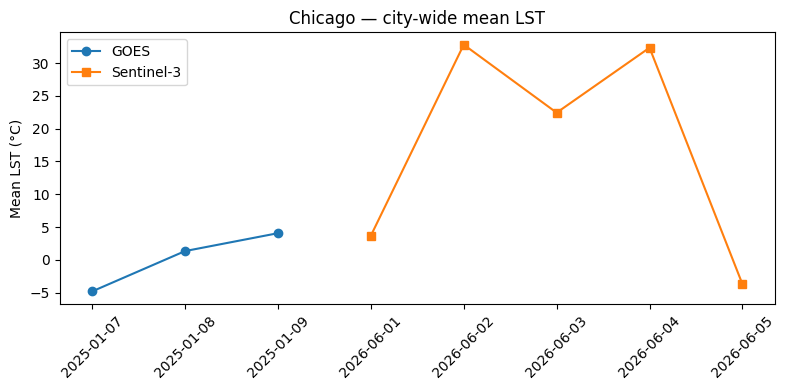

In [10]:
def daily_means(result):
    return [float(np.nanmean(band)) for band in result.array]

means_goes = daily_means(lst_goes)
means_s3 = daily_means(lst_s3)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lst_goes.dates, means_goes, "o-", label="GOES")
ax.plot(lst_s3.dates, means_s3, "s-", label="Sentinel-3")
ax.set_ylabel("Mean LST (°C)")
ax.set_title("Chicago — city-wide mean LST")
ax.legend()
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

---
## 6 — `source="both"` (GOES with Sentinel-3 fallback)

For each day, GOES is tried first (finer native resolution over the
Americas); Sentinel-3 fills in any day GOES has no usable scene for.

In [11]:
lst_both = lcz_get_lst(
    map_path,
    source="both",
    start_date="2025-01-05",
    end_date="2025-01-09",
    cache=True,
)
print("dates covered:", lst_both.dates)

dates covered: ['2025-01-05', '2025-01-06', '2025-01-07', '2025-01-08', '2025-01-09']


---
## 7 — Cache behavior

Repeating an identical call (same source/satellite/bbox/date range/target_hour,
regardless of `units`) hits the on-disk cache instead of re-downloading.

In [12]:
import time

t0 = time.time()
_ = lcz_get_lst(map_path, source="sentinel3",
                 start_date="2026-06-01", end_date="2026-06-02", cache=True)
print(f"cached call: {time.time() - t0:.3f}s")
print("cache file (always Kelvin):", lst_s3.path)

cached call: 0.007s
cache file (always Kelvin): /Users/co2map/.lcz4r_cache/lst_stack_5f6d840cf28a43ed.tif


---
## 8 — GOES coverage guard

`source="goes"` raises a clear error for areas outside the Americas,
pointing at `source="sentinel3"` instead of silently returning nothing.

In [13]:
berlin_map = lcz_get_map(city="Berlin", isave_map=False)

try:
    lcz_get_lst(berlin_map, source="goes",
                start_date="2025-01-01", end_date="2025-01-02", cache=False)
except ValueError as e:
    print("Raised as expected:", e)

Raised as expected: The LCZ map's area falls outside the GOES full-disk view.


---
## 9 — Surface Urban Heat Island (`lcz_uhi_surface`)

`lcz_uhi_surface` computes SUHI intensity from an `lcz_get_lst` stack,
stratified by LCZ class — the *surface* (satellite LST) counterpart to
`lcz_uhi_intensity`'s *canopy-layer* (station air temperature) UHI. These
are different physical quantities in the literature (Voogt & Oke 2003) —
not two ways of computing the same thing.

Seven methods, each grounded in a specific strand of the SUHI literature
(see the module docstring for full citations):

| method | what it computes | reference |
|---|---|---|
| `urban_rural` | per-date mean(LST\|urban) − mean(LST\|rural) | Voogt & Oke 2003 |
| `percentile` | same, rural reference = a low percentile instead of the mean | Imhoff et al. 2010 |
| `lcz` | per-class ΔT vs. LCZ 14 ("Low plants") | Chakraborty & Lee 2019, WUDAPT |
| `utfvi` | (LST−mean)/mean in Kelvin, 6 ecological categories | Liu & Zhang 2011 |
| `hotspot` | Getis-Ord Gi* spatial hot/cold spots | Ord & Getis 1995 |
| `transect` | LST anomaly binned by distance from the urban core | Zhou et al.'s gradient method |
| `persistence` | % of dates a pixel exceeded the rural reference (novel) | — |

We'll fetch a fresh multi-day LST stack for Rio de Janeiro (outside the
GOES view, so Sentinel-3) to have several dates to work with.


In [14]:
rio_map_path = lcz_get_map(city="Rio de Janeiro", isave_map=False)

lst_rio = lcz_get_lst(
    rio_map_path, source="sentinel3",
    start_date="2024-07-01", end_date="2024-07-10",
    units="K", cache=True,
)
print("dates:", lst_rio.dates)
print("shape:", lst_rio.array.shape)


dates: ['2024-07-02', '2024-07-03', '2024-07-06', '2024-07-08', '2024-07-09', '2024-07-10']
shape: (6, 376, 777)


### 9.1 — `urban_rural`: the classic time series

Straightforward, and the one number most SUHI papers lead with.


In [ ]:
from LCZ4py import lcz_uhi_surface

ur = lcz_uhi_surface(rio_map_path, lst_rio, method="urban_rural")
print(ur.df)
display(ur.fig)

### 9.2 — `lcz`: per-class ΔT vs. LCZ D

Every built-up class should come out warmer than the LCZ 14 reference
(by construction, LCZ 14 itself is exactly 0).


In [ ]:
lcz_delta = lcz_uhi_surface(rio_map_path, lst_rio, method="lcz")
print(lcz_delta.df.group_by("lcz").agg(pl.col("delta_t").mean()).sort("lcz"))
display(lcz_delta.fig)


### 9.3 — `utfvi`: ecological thermal categories

Liu & Zhang's six-category classification, for the most recent date by
default (`date_index=-1`-equivalent — pass `date_index=` to pick another).


In [ ]:
utfvi = lcz_uhi_surface(rio_map_path, lst_rio, method="utfvi")
print(utfvi.df)
for panel_name, panel_fig in utfvi.fig.items():
    print(f"[{panel_name}]")
    display(panel_fig)


### 9.4 — `hotspot`: Getis-Ord Gi*

Significant spatial clusters of high/low LST, computed via a local moving
window (no vector weights matrix — see the module docstring for why that
matters at raster scale). We pick a date without cloud contamination
(`date_index=2`, 2024-07-06) — see §9.6 for why that matters.


In [ ]:
hotspot = lcz_uhi_surface(rio_map_path, lst_rio, method="hotspot", hotspot_window=5, date_index=2)
print(hotspot.df)
display(hotspot.fig)


### 9.5 — `transect`: urban-rural gradient profile

The classic decreasing-with-distance curve — LST anomaly (vs. the day's
rural reference) binned by distance from the nearest urban pixel.


In [ ]:
transect = lcz_uhi_surface(rio_map_path, lst_rio, method="transect", n_bins=8, date_index=2)
display(transect.fig)


### 9.6 — `persistence`: a novel view for this package

Standard SUHI maps show one date's snapshot. This instead asks "how
*reliably* is this pixel part of the heat island across the whole
observation record?" — only possible because `lcz_get_lst` already returns
a multi-date stack. "Bare rock or paved" and dense urban classes should
come out most persistently hot; water and dense trees least.


In [ ]:
persistence = lcz_uhi_surface(rio_map_path, lst_rio, method="persistence", persistence_threshold=1.0)
print(persistence.df.sort("persistence", descending=True))
for panel_name, panel_fig in persistence.fig.items():
    print(f"[{panel_name}]")
    display(panel_fig)


### 9.7 — A real data-quality caveat, found while writing this tutorial

Two of the six fetched dates (2024-07-02 and 2024-07-10) turned out to
have unmasked cloud contamination in the Sentinel-3 LST — `lcz_get_lst`'s
GOES path filters on the `DQF` quality flag, but its Sentinel-3 path
currently doesn't. This showed up directly in the `percentile` method: a
low percentile of "rural" LST can land on a cold cloud pixel instead of
clear-sky land, producing a spuriously enormous "SUHI".


In [21]:
suspect = lcz_uhi_surface(rio_map_path, lst_rio, method="percentile", percentile=10, iplot=False)
print(suspect)
print()
print("Compare to the urban_rural (mean-based) results from §9.1 — the two")
print("dates above with suhi >> 10 are the cloud-contaminated ones; the rest")
print("agree closely with the mean-based method, as expected.")


shape: (6, 6)
┌────────────┬────────────┬────────────┬───────────┬─────────┬─────────┐
│ date       ┆ urban      ┆ rural      ┆ suhi      ┆ n_urban ┆ n_rural │
│ ---        ┆ ---        ┆ ---        ┆ ---       ┆ ---     ┆ ---     │
│ str        ┆ f64        ┆ f64        ┆ f64       ┆ i64     ┆ i64     │
╞════════════╪════════════╪════════════╪═══════════╪═════════╪═════════╡
│ 2024-07-02 ┆ 282.799561 ┆ 256.902008 ┆ 25.897552 ┆ 70354   ┆ 57572   │
│ 2024-07-03 ┆ 299.183624 ┆ 296.25     ┆ 2.933624  ┆ 70360   ┆ 57598   │
│ 2024-07-06 ┆ 290.022614 ┆ 286.395996 ┆ 3.626617  ┆ 70408   ┆ 57625   │
│ 2024-07-08 ┆ 292.858612 ┆ 290.243988 ┆ 2.614624  ┆ 70360   ┆ 57607   │
│ 2024-07-09 ┆ 286.976715 ┆ 286.014008 ┆ 0.962708  ┆ 70408   ┆ 57627   │
│ 2024-07-10 ┆ 292.795441 ┆ 270.019989 ┆ 22.775452 ┆ 70408   ┆ 57631   │
└────────────┴────────────┴────────────┴───────────┴─────────┴─────────┘

Compare to the urban_rural (mean-based) results from §9.1 — the two
dates above with suhi >> 10 are the cloud

### 9.8 — Every method at once

`method="all"` returns a dict keyed by method name; `iplot=False` collapses
each result to its bare DataFrame.


In [22]:
all_suhi = lcz_uhi_surface(rio_map_path, lst_rio, method="all")
print("methods:", sorted(all_suhi))
print("hotspot categories:", all_suhi["hotspot"].df["category"].to_list())


methods: ['hotspot', 'lcz', 'percentile', 'persistence', 'transect', 'urban_rural', 'utfvi']
hotspot categories: ['Cold spot', 'Not significant']


---
## Summary

- `lcz_get_lst(lcz_map_path, source, start_date, end_date, units="C", ...)`
  returns an `LCZLSTResult` with a `(n_days, H, W)` float32 `array` in the
  requested units (NaN outside the LCZ map's valid pixels or on days with
  no usable scene) and a matching `dates` list.
- `units`: `"C"` (default) or `"K"`. The on-disk cache always stores Kelvin,
  so switching units is free — no re-download.
- `source="goes"`: Americas only, ~2km, sparser due to cloud masking,
  archive currently ends ~April 2025.
- `source="sentinel3"`: global, ~1km, current, 1-2 overpasses/day.
- `source="both"`: GOES first, Sentinel-3 fills gaps.
- `lcz_plot_map(result.path, band=...)` plots any single date from the
  stack as a static matplotlib figure (pass `renderer="plotly"` for the
  interactive Plotly figure) — it auto-detects the continuous LST data
  (vs. a categorical LCZ map) and labels the colorbar from the file's
  `units` tag.
- Repeated calls with identical parameters are served from
  `~/.lcz4r_cache` instead of re-downloading.
- `lcz_uhi_surface(lcz_map, lst_x, method=...)` computes Surface UHI intensity from an `lcz_get_lst` stack: `"urban_rural"`/`"percentile"` (classic mean-difference), `"lcz"` (per-class ΔT vs. LCZ 14), `"utfvi"` (Liu & Zhang ecological categories), `"hotspot"` (Getis-Ord Gi*), `"transect"` (urban-rural gradient), `"persistence"` (novel: % of dates a pixel stayed part of the heat island), or `"all"` for every method as a dict (§9).